# How far bans and token vetoes push Qwen3-8B: `method.py` demo (token walk)

**Artifact** `art_ccAbfJVcv0LO` (iteration 3, step 4) · **Model** `Qwen/Qwen3-8B`: bf16 for the path tasks T1/T2, the official FP8 checkpoint for the bench tasks T03/T04/T06/T10 · **Data** `mini_demo_data.json`, loaded from GitHub with a local fallback

**Question.** Asked to write a path-search function, Qwen3-8B writes BFS almost every time. Is the algorithm decided at a few decisive tokens? If those tokens are made impossible, does the model step one "rung" deeper into its repertoire of known algorithms, and eventually reach something new? The experiment compares three knobs:

| part | knob | what is measured |
|---|---|---|
| **4b token walk** (this demo) | persistent logit **veto** of the default's distinctive token n-gram: a per-request vLLM logits processor (`src/veto.py`) | does each veto move the model to the next algorithm? |
| 4a prompt reach | prompt bans that leave one survivor; two-step bans | *will* (writes X when everything else is banned) vs *can* (writes X when asked for it) |
| 4c long-form novelty | "make a (fully) novel algorithm" with a 2,000-word rationale, thinking off and on | does any program contain a new algorithm? |

`method.py` is the experiment's entry point. Its commands run the GPU phases (`src/*.py`: vLLM server, generation, labelling, judging). Its default command, `outputs`, calls `assemble_outputs()`, which turns the saved generations, the committed forecasts and the analysis results into `method_out.json`.

**This notebook** splits `method.py` into cells and runs the `outputs` command on a curated subset of the token-walk dataset: 100 of its 1,750 generations, covering every task, step, mask round and control arm. It also re-verifies the preregistration hash chain and plots the full-run walk. The generation itself (Qwen3-8B with the veto processor on an NVIDIA L4, hours of decoding) cannot run here; its saved outputs ship in the data file.

**How the token walk works**
1. *Step 0.* 50 programs per task under **neutral twins**: the ban sentence "Do not use {N} for this task." with the algorithm's name replaced by neutral nouns ("man, the house and the baby") and padded to the ban's exact token length. The model writes its default.
2. *Step 1.* The default's **distinctive n-gram** is vetoed. That is a run of lexical tokens present in at least 80% of the default's programs and as rare as possible in other algorithms' programs, e.g. `' c, path = queue.p'` for BFS. Whenever the last generated tokens equal the n-gram's prefix, the logit of its final token is set to −∞, so the sequence can never be emitted.
3. Up to two **extra mask rounds** per step add the spellings that leaked past the veto (`'(parent'`, `'parents'`, …) or the re-emerged programs' own distinctive n-gram.
4. A new landing algorithm (rung 2) is vetoed next, and so on. The walk **stalls** when the vetoed algorithms keep coming back.

Controls: a **sham** veto of an algorithm-generic n-gram of matched length (e.g. `' start == goal:\n'`), and on T1 a **fixed TOP5** veto of the BFS, DFS, IDDFS and A*/greedy n-grams at once.

| task | problem | precision | default algorithm |
|---|---|---|---|
| T1 | path between two cells of a grid | bf16 | BFS |
| T2 | weighted shortest path | bf16 | Dijkstra |
| T03 | k-th smallest value | FP8 | full sort |
| T04 | substring search | FP8 | naive scan |
| T06 | find the duplicate | FP8 | hash set |
| T10 | connected components | FP8 | union-find |

**Full-run result.** The veto is exact: 0 banned-sequence occurrences in 1,450 vetoed generations. Yet the walk **stalled on all six tasks**, at rung 1 on five of them and at rung 2 (sort + adjacent) on T06. The default came back under new names (`current_row`/`current_col`), through other spellings of the vetoed string, or the code broke into near-miss syntax. The sham veto left the default in place.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# demo: method.py's module docstring (its `help` command prints it, see main() below)
__doc__ = """Step 4 of iteration 3 on Qwen3-8B: how far can bans and token vetoes push?

  (4b) TOKEN WALK - cumulative persistent logit vetoes of each landed algorithm's distinctive token n-gram under
       the neutral twins (no ban text), with a matched SHAM veto and (T1) a fixed TOP5 veto as controls;
  (4a) PROMPT REACH - leave-one-survivor ban lists (bench) and two-step bans (all tasks) scored as 'will' against
       forced 'can', with the C3 prediction and a preregistered list-independence test;
  (4c) LONG-FORM NOVELTY - the request's two 2,000-word-rationale instructions, thinking off and on, every
       correct off-catalogue program audited by two blind judges plus a manual pass against human/known solutions.

Baselines in the same pipeline: step 0 (neutral twins, no veto) for every veto arm; the prompt-ban comparators for
the veto; the sham veto (matched random control); forced 'can' (capability ceiling).

Usage (the order actually run; see README.md):
  uv run method.py s0                      # input copies, SHA256SUMS, bench commitment check
  uv run method.py server bf16 start       # PID-managed vLLM server (bf16, max_model_len 4608)
  uv run method.py unit bf16               # veto unit tests u1-u4 + n-gram unit tests
  uv run method.py phase A                 # T1/T2 walk + shams + fixed-TOP5 (+ committed forecasts, two-step)
  uv run method.py longform bf16           # thinking-off long-form, bf16 branch (concurrently with phase A)
  uv run method.py server bf16 stop; uv run method.py server fp8 start
  uv run method.py phase B                 # bench walk + shams, LOS after step-1 commit, two-step after step 2
  uv run method.py longform fp8_off 50     # FP8 cross-check copy + bench long-form
  uv run method.py longform fp8_on T1:10,T2:10
  uv run method.py audit corpus|controls|pool|claims
  uv run method.py analyze                 # results/*.json + figures
  uv run method.py outputs                 # method_out.json (+ full/mini/preview); also the default with no argument
"""

import json
import subprocess
import sys
from collections import Counter
from pathlib import Path

# demo: method.py sets ROOT = Path(__file__).resolve().parent (the artifact folder with src/, data/, results/, ...)
# and puts ROOT / "src" on sys.path. A notebook has no __file__ and the demo ships no src/: here ROOT is the folder
# that the rebuilt method_out.json (and logs/method.log) are written to; every input comes from mini_demo_data.json.
ROOT = Path("method_demo_out")
# sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402

# demo: the names method.py imports from src/config.py are copied into the "src/config.py" cell below
# from config import (ALL_TASKS, DATA, PRED, RESULTS, TASKS, read_jsonl, setup_logging, utc_now,  # noqa: E402
#                     write_json)

# Additional imports for the notebook: helpers copied from src/config.py and src/commit.py, result tables and plots
import hashlib
from datetime import datetime, timezone
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-18/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(data["about"]["description"])
print("token-walk generations shipped:", data["about"]["n_rows_selected"],
      "| in the full run:", data["about"]["n_rows_full_run"])
print("files shipped:", len(data["files"]), "| neutral-twin prompts for tasks:", list(data["neutral_twins"]))

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated subset of the token-walk generations of Qwen3-8B (step-0 baseline, cumulative distinctive n-gram veto walk, matched sham veto, fixed TOP5 veto) on six tasks, plus every file method.py's assemble_outputs() reads to build method_out.json for them.
token-walk generations shipped: {'walk': 81, 'sham': 10, 'fixed_top5': 9} | in the full run: {'walk': 1400, 'sham': 200, 'fixed_top5': 150}
files shipped: 75 | neutral-twin prompts for tasks: ['T1', 'T2', 'T03', 'T04', 'T06', 'T10']


## Configuration

`method.py` has no numeric hyper-parameters of its own. Its command-line argument picks a pipeline stage, and only `outputs` (the default) and `help` work without the GPU stack. The demo-scale knob is how many of the shipped generations per (arm, task, step, round) group go into `assemble_outputs()`. The rows in `mini_demo_data.json` are ordered most informative first, so `ROWS_PER_GROUP = 1` already gives one representative program for every bar of the walk. The generation parameters of the original GPU phases are listed in the cell's comments for reference. The whole notebook runs in about 15 seconds at any setting, mostly spent on the install cell.

In [5]:
# method.py command (method.py reads it from sys.argv[1]; default "outputs"). Only "outputs" (rebuild method_out.json
# from saved data) and "help" run in this notebook. s0 / server / unit / phase / longform / audit / analyze drive the
# vLLM GPU phases through src/*.py (Qwen3-8B on an NVIDIA L4, hours of decoding), which the demo does not ship.
CMD = "outputs"
CMD_ARGS: list[str] = []    # method.py: sys.argv[2:], e.g. ["bf16", "start"] for `server`, ["A"] for `phase`

# Demo scale: shipped token-walk generations used per (arm, task, step, round) group. mini_demo_data.json holds 2-4
# per group (100 rows over 35 groups); None = all of them.
ROWS_PER_GROUP = None       # all 100 shipped rows (tested at 1 -> 2 -> None). Original run: all 50 per group
                            # (1,750 rows: 1,400 walk + 200 sham + 150 fixed TOP5, in the artifact's data/)

# Results section: number of vetoed programs printed next to a step-0 (no veto) program of the same task
N_CODE_EXAMPLES = 2
EXAMPLE_TASK = "T1"         # any of T1, T2, T03, T04, T06, T10

# For reference, the original GPU-phase parameters (src/config.py; used by `phase A/B`, not by assemble_outputs):
#   N_PER_TEMPLATE = 10 programs x 5 templates W1-W5 = 50 per walk step / mask round; WALK_MAX_STEPS = 5;
#   WALK_MAX_EXTRA_ROUNDS = 2; LEAK_THRESHOLD = 0.05; REEMERGE_THRESHOLD = 0.20; NGRAM_PRESENCE = 0.8;
#   decoding: temperature 1.0, top_p 1.0, top_k -1 (pure sampling), max_tokens 1024, thinking off.

## Shared names from `src/config.py`

`method.py` imports its folder paths, the **task registry** and a few utilities from `src/config.py`. They are copied here verbatim, with one systematic change, marked `# demo:`. A file that the original reads from the artifact folder is looked up in `data["files"]` under the same relative path; for example, `PRED / "reach_forecasts_path.json"` becomes `"predictions/reach_forecasts_path.json"`.

For every task the registry holds the catalogue of known algorithms (the labels the labeller can assign, plus `other` for an unknown algorithm and `invalid` for missing or broken code) and the **default**, the algorithm the model writes when nothing stops it. `_fill_bench()` completes the four bench tasks from their `spec.json` (catalogue, display names, task text).

In [6]:
# ---- from src/config.py ----
# demo: every input file is looked up in FILES by its path relative to the artifact folder; only ROOT (set in the
# imports cell) and LOGS are real folders. FILES is a copy of data["files"], so the demo-scale cell can be re-run.
FILES = dict(data["files"])

INPUTS = Path("inputs")
DATA = Path("data")
RESULTS = Path("results")
PRED = Path("predictions")
LOGS = ROOT / "logs"
COMMIT_LOG = Path("commitments.log")
for _d in (ROOT, LOGS):     # demo: config.py creates (DATA, RESULTS, PRED, FIGS, LOGS) inside the artifact folder
    _d.mkdir(parents=True, exist_ok=True)

BENCH_DIR = INPUTS / "bench"          # copy of exp11 bench (frozen; verified against bench/commitment.json)

# ------------------------------------------------------------------------------------------------ tasks
# T1/T2 labels are the exp1 canonical suite labels (suite/common.py CATALOGUE); A* and greedy best-first share
# 'astar_gbfs', and 'dijkstra' on T1 is unit-weight Dijkstra.  Display names are exp7's v2 names as frozen in
# exp8 prompts/frozen_prompts.json.
TASKS: dict[str, dict[str, Any]] = {
    "T1": {"family": "path", "suite": "t1", "default": "bfs",
           "catalogue": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
           "display": {"bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)",
                       "bibfs": "bidirectional BFS", "iddfs": "iterative deepening DFS (IDDFS)",
                       "astar_gbfs": "A* search", "dijkstra": "unit-weight Dijkstra"},
           "signature": "def solve(grid, start, goal):", "dtype": "bf16"},
    "T2": {"family": "path", "suite": "t2", "default": "dijkstra",
           "catalogue": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"],
           "display": {"dijkstra": "Dijkstra's algorithm", "bf_spfa": "Bellman-Ford or SPFA",
                       "bidijkstra": "bidirectional Dijkstra", "floyd": "Floyd-Warshall",
                       "dial": "Dial's bucket-queue algorithm"},
           "signature": "def solve(n, edges, s, t):", "dtype": "bf16"},
    "T03": {"family": "bench", "bench": "T03", "task_id": "T03_kth_smallest", "default": "full_sort",
            "analysis_set": ["full_sort", "quickselect", "size_k_heap", "counting_sort", "heapify_pop"],
            "signature": "def solve(nums, k):", "dtype": "fp8"},
    "T04": {"family": "bench", "bench": "T04", "task_id": "T04_substring_search", "default": "naive",
            "analysis_set": ["naive", "kmp", "rabin_karp", "builtin", "z_algorithm"],
            "signature": "def solve(haystack, needle):", "dtype": "fp8"},
    "T06": {"family": "bench", "bench": "T06", "task_id": "T06_find_duplicate", "default": "hash_set",
            "analysis_set": ["hash_set", "value_binary_search", "floyd", "sort_adjacent"],
            "signature": "def solve(nums):", "dtype": "fp8"},
    "T10": {"family": "bench", "bench": "T10", "task_id": "T10_connected_components", "default": "union_find",
            "analysis_set": ["bfs", "dfs", "union_find"],
            "signature": "def solve(n, edges):", "dtype": "fp8"},
}
PATH_TASKS = ["T1", "T2"]
BENCH_TASKS = ["T03", "T04", "T06", "T10"]
ALL_TASKS = PATH_TASKS + BENCH_TASKS
OFF_LABELS = ("other", "invalid")


def load_spec(task: str) -> dict[str, Any]:
    return json.loads(FILES[str(BENCH_DIR / TASKS[task]["task_id"] / "spec.json")])   # demo: was (...).read_text()


def _fill_bench() -> None:
    for t in BENCH_TASKS:
        s = load_spec(t)
        TASKS[t]["catalogue"] = [c["mode"] for c in s["catalogue"]]
        TASKS[t]["display"] = {c["mode"]: c["display_name"] for c in s["catalogue"]}
        TASKS[t]["description"] = s["description"]
        TASKS[t]["spec_text"] = s["spec_text"]
        TASKS[t]["aliases"] = s["aliases"]
        sig = s["signature"]
        TASKS[t]["signature"] = f"def {sig}:"


_fill_bench()


# ------------------------------------------------------------------------------------------------ utils
def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if str(p) not in FILES:     # demo: was `if not p.exists()`
        return []
    return list(FILES[str(p)])  # demo: shipped as a list of parsed rows (was json.loads of every non-empty line)


def write_json(p: Path, obj: Any) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=1, default=str))


def setup_logging(name: str) -> None:
    from loguru import logger

    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


for _t in ALL_TASKS:
    print(f"{_t:4s} default {TASKS[_t]['default']:11s} catalogue {TASKS[_t]['catalogue']}")

T1   default bfs         catalogue ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra']
T2   default dijkstra    catalogue ['dijkstra', 'bf_spfa', 'bidijkstra', 'floyd', 'dial']
T03  default full_sort   catalogue ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T04  default naive       catalogue ['naive', 'kmp', 'rabin_karp', 'z_algorithm', 'bmh', 'builtin']
T06  default hash_set    catalogue ['hash_set', 'sort_adjacent', 'floyd', 'value_binary_search', 'index_marking']
T10  default union_find  catalogue ['bfs', 'dfs', 'union_find', 'label_propagation']


## Neutral-twin prompts (`src/prompts.py`)

The walk never states a ban. Every generation uses one of five **neutral twins** (templates W1–W5) of the default's single ban, so the only intervention is the logit veto. For T1/T2 these are the frozen twins of an earlier experiment (exp8). For the bench tasks the algorithm's name is replaced by a neutral noun and padded with `' .'` until the chat-formatted prompt has exactly as many tokens as the real ban (`ban_tokens == neutral_tokens`).

The original renders them from the artifact's `inputs/` with the Qwen3-8B tokenizer. The demo ships the rendered result. When the data file was built, every shipped generation's recorded `prompt_sha256` matched `sha256(user_text)` of its template.

In [7]:
# ---- from src/prompts.py ----
# demo: the original builds the twins from inputs/ (exp8 frozen prompts, bench neutral nouns) with the Qwen3-8B
# tokenizer and asserts their token ids; the rendered twins (without 'ids') are shipped in data["neutral_twins"].
# ban_prompt / longform_prompt are not needed: they render the prompt_reach / long_form rows, not shipped here.
def neutral_twins(task: str) -> dict[str, dict[str, Any]]:
    """W1-W5 neutral twins of the single ban of the task's default (the walk's ban-free frame)."""
    return data["neutral_twins"][task]


for _t in ("T1", "T03"):
    _w = neutral_twins(_t)["W1"]
    print(f"--- {_t} W1: {_w['neutral_tokens']} tokens (the real ban: {_w['ban_tokens']}); {_w['source']}")
    print(_w["user_text"][:420], "...\n")
_k = sum(sha256_text(neutral_twins(r["task"])[r["template"]]["user_text"]) == r["prompt_sha256"]
         for a in ("walk", "sham", "fixed_top5") for r in FILES[f"data/samples_{a}.jsonl"])
print(f"prompt_sha256 of shipped generations reproduced by their twin: {_k}/{data['about']['n_rows_total']}")

--- T1 W1: 246 tokens (the real ban: 246); exp8 frozen_prompts.json neutral_A
Do not use man, the house and the baby for this task.

Task: write a Python function solve(grid, start, goal) that finds a path between two cells of a grid. grid is a list of equal-length strings with between 1 and 30 rows and between 1 and 30 columns; the character . is a free cell and the character # is a wall. start and goal are (row, col) tuples of 0-based indices. A move goes to one of the 4 orthogonal neighbour ...

--- T03 W1: 188 tokens (the real ban: 188); bench neutral_nouns.json[full_sort] noun 0, ' .' padding
Do not use man for this task. . .

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for t

## The preregistration hash chain (`src/commit.py`)

Every forecast and every veto mask was written to `predictions/` and **committed before the samples it governs**. `commitments.log` gets one line per file with the file's sha256 and a running chain hash, `chain = sha256(prev_chain + sha256)`, so no committed file can be edited, and no line inserted or dropped, without breaking the chain. `verify_chain()` recomputes both and `assemble_outputs()` stores the result in the metadata.

The demo ships all committed files byte-exact (the masks `predictions/walk_*`, `sham_*` and `fixed_top5_*`, the forecasts, and three analysis scripts), so the check below is real. The expected result is 49 entries with exactly one failure, `src/analysis.py` v1. That is deviation D17: the analysis script was extended after it was committed. The extended file has its own, later chain entry, and the never-edited `src/rederive.py` re-derives every preregistered number independently, with 0 mismatches.

In [8]:
# ---- from src/commit.py ----
def verify_chain() -> dict[str, Any]:
    prev = "0" * 64
    n, bad = 0, []
    if str(COMMIT_LOG) not in FILES:                  # demo: was `if not COMMIT_LOG.exists()`
        return {"n": 0, "ok": True, "bad": []}
    for line in FILES[str(COMMIT_LOG)].splitlines():  # demo: was COMMIT_LOG.read_text().splitlines()
        if not line.strip():
            continue
        r = json.loads(line)
        n += 1
        ok = r["prev_chain"] == prev and r["chain"] == hashlib.sha256((prev + r["sha256"]).encode()).hexdigest()
        p = r["path"]                                 # demo: was ROOT / r["path"]
        file_ok = p in FILES and sha256_text(FILES[p]) == r["sha256"]  # demo: was p.exists() and sha256_file(p) == ...
        if not (ok and file_ok):
            bad.append({"label": r["label"], "path": r["path"], "chain_ok": ok, "file_ok": file_ok})
        prev = r["chain"]
    return {"n": n, "ok": not bad, "bad": bad, "head": prev}


print(json.dumps(verify_chain(), indent=1))
_m = json.loads(FILES["predictions/walk_T1_s1_r0.json"])
print(f"\ncommitted mask: {_m['arm']} {_m['task']} step {_m['step']} round {_m['round']} (written {_m['utc']})\n"
      f"  vetoes {[i['string'] for i in _m['mask_items']]} as {len(_m['veto_seqs'])} token-id sequences "
      f"{_m['veto_seqs']}\n  for the {len(_m['seeds'])} seeds of that round")

{
 "n": 49,
 "ok": false,
 "bad": [
  {
   "label": "code sha256 analysis.py before bench ban samples",
   "path": "src/analysis.py",
   "chain_ok": true,
   "file_ok": false
  }
 ],
 "head": "a4f108d2a29f6406def1094b267273653b71f549fd0e9185527b170df7fece90"
}

committed mask: walk T1 step 1 round 0 (written 2026-10-20T21:30:44.329354Z)
  vetoes [' c, path = queue.p'] as 3 token-id sequences [[272, 11, 1815, 284, 7177, 556], [198, 66, 11, 1815, 284, 7177, 556], [66, 11, 1815, 284, 7177, 556]]
  for the 50 seeds of that round


## Demo scale: which generations are processed

This step is not part of `method.py`. It keeps the first `ROWS_PER_GROUP` shipped generations of every (arm, task, step, round) group. Within a group the data file lists the modal label first, then the second most frequent label, then rarer labels, string leaks and labelled-but-failing programs. Every row is a verbatim copy of a line of the artifact's `data/samples_{walk,sham,fixed_top5}.jsonl`. Its fields include the program (`code`), its label and test result, the number of vetoed token sequences, `veto_occurrences` (how often a vetoed sequence appears in the output ids) and `string_leak` (whether a vetoed string re-appeared in a different tokenisation).

In [9]:
def _first_k_per_group(rows: list[dict[str, Any]], k: int | None) -> list[dict[str, Any]]:
    if k is None:
        return list(rows)
    seen, out = Counter(), []
    for r in rows:
        g = (r["arm"], r["task"], r.get("step"), r.get("round"))
        if seen[g] < k:
            out.append(r)
            seen[g] += 1
    return out


for _arm in ("walk", "sham", "fixed_top5"):
    _p = f"data/samples_{_arm}.jsonl"
    FILES[_p] = _first_k_per_group(data["files"][_p], ROWS_PER_GROUP)
print(f"ROWS_PER_GROUP = {ROWS_PER_GROUP}: generations to process",
      {_arm: len(FILES[f"data/samples_{_arm}.jsonl"]) for _arm in ("walk", "sham", "fixed_top5")})
print("fields of one generation row:", list(FILES["data/samples_walk.jsonl"][0]))

ROWS_PER_GROUP = None: generations to process {'walk': 81, 'sham': 10, 'fixed_top5': 9}
fields of one generation row: ['model', 'engine_dtype', 'task', 'condition', 'arm', 'template', 'sample_id', 'seed', 'prompt_sha256', 'label', 'labeller_source', 'runtime_label', 'ast_label', 'judge_label', 'passed', 'finish_reason', 'n_new_tokens', 'code_sha256', 'code', 'step', 'round', 'n_veto_seqs', 'veto_occurrences', 'fires', 'string_leak', 'leak_detail']


## `method.py` (1/4): the subprocess helper

The GPU commands of `method.py` run scripts in `src/` with the artifact's own virtual environment (`.venv`: vLLM 0.11, torch 2.8) through `run()`. Those scripts are `server.py` (PID-managed vLLM server with the veto plugin), `phases.py` and `walk.py` (the walk, shams and fixed TOP5), `longform.py`, `audit.py` and `analysis.py`. The helper is kept unchanged. Only the commands that cannot run in this notebook call it.

In [10]:
PY = str(ROOT / ".venv" / "bin" / "python")


def run(args: list[str]) -> None:
    logger.info("$ " + " ".join(args))
    subprocess.run([PY] + args, cwd=str(ROOT), check=True)

## `method.py` (2/4): the deviation log

`DEVIATIONS` records every departure from the preregistered plan, D1 to D17. They cover the hardware (an L4 instead of the planned GPU), precision chosen per task family, the rule that vetoed n-grams must be lexical (D3: a whitespace n-gram was bypassed by re-indenting in 20/20 samples), how shams are constructed (D4: none exists for T03/T06), the timing of forecast commits, the dropped optional analyses (D10: no internal-state claims) and the late edit of `analysis.py` (D17). `assemble_outputs()` copies the list into the metadata unchanged.

In [11]:
DEVIATIONS = [
    {"id": "D1", "what": "Hardware: NVIDIA L4 (23 GB, 300 GB/s) instead of the planned RTX A4500 (20 GB, 640 GB/s); "
                         "6 CPUs (cgroup quota 5.1), 57 GB RAM.",
     "consequence": "bf16 decode measured at ~250-410 tok/s for short programs and ~84 tok/s (shared GPU) for long-form."},
    {"id": "D2", "what": "Precision by task family instead of bf16 for every short arm: T1/T2 arms in bf16 (their "
                         "reference programs and 'can' came from bf16 exp8/exp9), bench arms (T03/T04/T06/T10) on the "
                         "official Qwen3-8B-FP8 checkpoint (their pilot programs, forced programs and 'can' came from "
                         "FP8 exp11), weight-only FP8 Marlin kernels (no C compiler for Triton).",
     "consequence": "each family is compared with references of its own precision; the bf16-vs-FP8 cross-check on "
                    "LF1-T2 bounds the precision effect for one task only."},
    {"id": "D3", "what": "Distinctive n-gram candidates must be lexical: an n-gram containing a whitespace-only token "
                         "(indentation / newline) is format-unsafe. Added after veto unit test u1: the first choice for "
                         "T2 (' dist[u]:\\n' + 11 spaces) was bypassed by re-indenting in 20/20 samples.",
     "consequence": "the plan's selection rule (argmin max collateral; ties -> smaller n) is otherwise unchanged."},
    {"id": "D4", "what": "Sham n-grams may not contain a Python keyword or the fence tag 'python' (a keyword veto breaks "
                         "syntax) and may not equal the distinctive n-gram; bench shams for T03 and T06 are reported as "
                         "NOT_CONSTRUCTIBLE (no algorithm-generic n-gram exists in their 3-6-line default programs); "
                         "T04 and T10 shams were run.",
     "consequence": "sham controls exist for T1, T2, T04, T10."},
    {"id": "D5", "what": "Unit test u2 compares no-veto requests alone vs interleaved with vetoed rows on the same "
                         "server (17/20 token-identical); a processor-free engine was not loaded (a second ~6 min load).",
     "consequence": "u2 measures plugin/batch invariance and vLLM batch nondeterminism together."},
    {"id": "D6", "what": "Forecast commits per family: the path forecasts were committed after T1/T2 walk step 1 "
                         "(bf16 phase), the bench forecasts after the bench walk step 1 (FP8 phase); each precedes every "
                         "ban sample it scores.",
     "consequence": "the commit is not a single six-task commit, but no forecast follows its samples."},
    {"id": "D7", "what": "T1 and T2 walks STALLED at step 1, so R2 for their two-step bans came from the plan's fallback "
                         "chain (no non-default catalogue label had >= 5 attempts) = the realised exp8/exp9 single-ban "
                         "substitutes (T1 DFS, T2 BF/SPFA), flagged.",
     "consequence": "the path two-step bans replicate the iteration-1 two-step design."},
    {"id": "D8", "what": "A client bug (an asyncio semaphore bound to the first event loop) crashed phase A when the "
                         "two-step batch was queued; no sample of that batch had been generated or written; the "
                         "two-step bans were run by `phases.py two_step path bf16` from the committed forecasts.",
     "consequence": "none on the data (same seeds, same prompts)."},
    {"id": "D9", "what": "Long-form thinking-off took the plan's 'split' branch (stage-10 projection 220 min > 60 min, "
                         "measured while sharing the GPU): bf16 LF1-T2 N=50, LF2-T2/LF1-T1/LF2-T1 N=25; FP8 cross-check "
                         "copy LF1-T2 N=50 and the bench cells on FP8.",
     "consequence": "T1/T2 LF cells other than LF1-T2 have N=25."},
    {"id": "D10", "what": "Optional O1 (manifold placement) and O2 (5b temperature sweep) dropped first, as the drop "
                          "order prescribes, because the L4 throughput left no room.",
     "consequence": "no internal-state claim of any kind."},
    {"id": "D11", "what": "exp9 forced labels (extended labeller) mapped onto the suite labels for T1 (astar and gbfs -> "
                          "astar_gbfs, dijkstra_unit -> dijkstra); T2 'can' for bidijkstra and dial taken from exp7 plain "
                          "attempts because exp9 ran only descriptive variants for them.",
     "consequence": "documented in results/can.json; both values are far below the C3 threshold of 0.7."},
    {"id": "D12", "what": "ASSOCIATE forecasts are unavailable for the path tasks (no association answers exist in the "
                          "path inputs).", "consequence": "the path two-step bans are scored against WALK2/SNAPBACK only."},
    {"id": "D13", "what": "Audit judge controls (T5) failed at round 0 (A 2/6, B 3/6; results/audit_controls_round0_failed"
                          ".json) because the audit prompt did not say the programs had been labelled 'other' by the "
                          "automatic labeller, and two controls were debatable (Counter-counting is a hash approach; "
                          "Sunday search is Horspool-like and T04's catalogue has BMH). The prompt gained that context "
                          "and a decision order (miss, degenerate, known variant, novel); the two controls were replaced "
                          "(hard-coded shortcut; value-range bisection). Round 1: A 5/6, B 5/6 (both call value-range "
                          "bisection a labeller miss). Judge models unchanged.",
     "consequence": "the audit ran with the round-1 prompt only."},
    {"id": "D14", "what": "Thinking-on: the floor (T1/T2, N=10 per prompt) ran; the first extension process (T1/T2 to N=25 plus bench T03/T04/T06 at N=10) was stopped after ~6 min when the KV cache saturated and nothing of it was written; the bench cells (N=10 per prompt) were re-launched alone after the thinking-off jobs ended and completed; the T1/T2 extension to N=25 was not re-run.",
     "consequence": "thinking-on cells have N=10 per prompt (upper bound on the novel rate ~26% per cell)."},
    {"id": "D15", "what": "The bf16 long-form job was restarted once with higher concurrency after the walk ended (its "
                          "stage-10 samples were kept; the interrupted batch had written nothing). The labeller-judge "
                          "client gained retries on HTTP 429/5xx after one rate-limit failure in phase B (that program "
                          "fell back to its runtime label, as the frozen combine rule prescribes).",
     "consequence": "none on the data."},
    {"id": "D16", "what": "Forecasts for the reach tests were committed per family before the samples they score; the "
                          "two disconfirming C3 cells (T03 quickselect, T10 BFS) got 'rung >= 3' from the flagged "
                          "fallback R2 because the walk stalled at step 1; a post hoc sensitivity with rung 2 := the "
                          "association answer is reported beside the preregistered verdict.",
     "consequence": "the preregistered verdict stands; the sensitivity shows which cell depends on the rung rule."},
    {"id": "D17", "what": "src/analysis.py was extended AFTER its sha256 was committed before the bench ban samples "
                          "(commitments.log line 42): labeller-miss-corrected compositions (required by the plan), the "
                          "post hoc association-rung sensitivity, the mechanism-level claim check and a Holm-family "
                          "note. No preregistered computation changed (will, the C3 cell/overall rule, the "
                          "list-independence permutation test). The committed bytes were not kept (no version control "
                          "here), so the v1 entry fails the file check in metadata.commitments; the extended file is "
                          "committed as a new chain entry, and src/rederive.py - written before that commit and never "
                          "edited - recomputes every preregistered number from raw rows with 0 mismatches.",
     "consequence": "the chain shows the edit instead of hiding it; the preregistered numbers are independently "
                    "re-derived."},
]

print(len(DEVIATIONS), "deviations:", ", ".join(d["id"] for d in DEVIATIONS))
print("D3:", DEVIATIONS[2]["what"])

17 deviations: D1, D2, D3, D4, D5, D6, D7, D8, D9, D10, D11, D12, D13, D14, D15, D16, D17
D3: Distinctive n-gram candidates must be lexical: an n-gram containing a whitespace-only token (indentation / newline) is format-unsafe. Added after veto unit test u1: the first choice for T2 (' dist[u]:\n' + 11 spaces) was bypassed by re-indenting in 20/20 samples.


## `method.py` (3/4): `assemble_outputs()`, the `outputs` command

This function builds `method_out.json = {"metadata": ..., "datasets": [...]}`:

1. **Committed forecasts.** For each task it reads `rung2[t]`, the walk's preregistered rung-2 forecast (where the model should land once its default is vetoed), and the C3 cells from `predictions/reach_forecasts_*.json`. It also reads the two-step-ban forecasts.
2. **One example per generation.** `ex_walk` turns a token-walk row into
   - `input`: the exact neutral-twin prompt;
   - `output`: `label|pass`. The label is the algorithm the labeller assigned (runtime behaviour plus AST rules, with an LLM judge on disagreement); `pass` means the program passed the task's tests;
   - `predict_*`: what the example is scored against. `predict_baseline_default` is the task's default. `predict_committed_forecast` is the default for step 0 and for the sham, `rung2[t]` for vetoed walk steps, and `n/a` for the fixed TOP5;
   - `metadata_*`: veto bookkeeping and the program itself.

   `ex_ban` and `ex_lf` do the same for prompt bans and long-form outputs, and a fourth dataset holds the novelty-audit records.
3. **Metadata.** Every analysis result (`results/*.json`), the deviation log, package versions and the verified hash chain.

Only token-walk rows ship with this demo. The original `if ban_rows:`, `if lf_rows:` and `if na.get("records"):` guards therefore skip the other three datasets, and `ex_ban`/`ex_lf` are defined but never called; they would need `ban_prompt`/`longform_prompt` and the Qwen3 tokenizer. Every `results/*.json` the function reads does ship, except the long-form judge claims and the audit's per-program records. The rebuilt metadata therefore equals the original apart from `utc` and `versions`, which describe this notebook's run. The only edits are marked `# demo:`: file reads go to `FILES`, and the `prompts`/`programs`/`commit` imports are replaced by the cells above.

In [12]:
def assemble_outputs() -> None:
    # demo: `from prompts import ban_prompt, longform_prompt, neutral_twins` -> neutral_twins is defined above (from
    # data); ban_prompt / longform_prompt only render the prompt_reach / long_form rows, which the demo does not ship.
    # demo: `from programs import can_table` is dropped (unused in this function; it needs the artifact's inputs/).

    # Committed forecasts that every example is scored against (predict_* fields, strings):
    #   predict_baseline_default    - the unconstrained baseline: the task's default algorithm (step 0, no veto/ban);
    #   predict_committed_forecast  - the forecast committed before the example's samples (walk: rung 2 = the landing
    #                                 after the default is vetoed; sham: the default survives; fixed TOP5: 'n/a');
    #   predict_survivor / predict_c3 (LOS rows) - the only allowed algorithm / C3's 'will <= 0.10' forecast;
    #   predict_walk2 / predict_associate / predict_snapback (two-step rows) - the three committed forecasts;
    #   predict_judge_a_code_mechanism / predict_judge_a_claims_novelty (long-form rows) - claim extraction (judge A).
    rung2, c3q = {}, {}
    for g in ("path", "bench"):
        p = PRED / f"reach_forecasts_{g}.json"
        if str(p) in FILES:                                         # demo: was p.exists()
            for t, v in json.loads(FILES[str(p)])["tasks"].items():  # demo: was p.read_text()
                rung2[t] = v["rung_table"]["R2"]["R2"]
                for c in v["c3_cells"]:
                    c3q[(t, c["S"])] = c["qualifies"]
    claims = {}
    cpath = RESULTS / "claims.json"
    if str(cpath) in FILES:                                         # demo: was cpath.exists() (not shipped)
        claims = {r["sample_id"]: (r.get("A") or {}) for r in json.loads(FILES[str(cpath)])["records"]}

    def default_of(t):
        return TASKS[t]["default"]

    def ex_walk(r):
        tw = neutral_twins(r["task"])
        t = r["task"]
        if r["arm"] == "walk":
            fcst = default_of(t) if (r.get("step") or 0) == 0 else str(rung2.get(t))
        elif r["arm"] == "sham":
            fcst = default_of(t)
        else:
            fcst = "n/a"
        return {"input": tw[r["template"]]["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(t), "predict_committed_forecast": fcst,
                "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_step": r.get("step"),
                "metadata_round": r.get("round"), "metadata_template": r["template"], "metadata_seed": r["seed"],
                "metadata_n_veto_seqs": r.get("n_veto_seqs"), "metadata_veto_occurrences": r.get("veto_occurrences"),
                "metadata_fires": r.get("fires"), "metadata_string_leak": r.get("string_leak"),
                "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason"), "metadata_thinking": False}

    fc = {}
    for g in ("path", "bench"):
        p = PRED / f"two_step_forecasts_{g}.json"
        if str(p) in FILES:                                         # demo: was p.exists()
            fc.update(json.loads(FILES[str(p)])["tasks"])           # demo: was p.read_text()

    def ex_ban(r):
        bp = ban_prompt(r["task"], r["template"], r["meta_banned"])
        e = {"input": bp["user_text"], "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
             "predict_baseline_default": default_of(r["task"]),
             "metadata_task": r["task"], "metadata_arm": r["arm"], "metadata_condition": r["condition"],
             "metadata_banned": r["meta_banned"], "metadata_template": r["template"], "metadata_seed": r["seed"],
             "metadata_engine_dtype": r["engine_dtype"], "metadata_labeller_source": r["labeller_source"],
             "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"), "metadata_thinking": False}
        if r["arm"] == "los":
            surv = r["condition"].split("LOS(", 1)[1].rstrip(")")
            e["predict_survivor"] = surv
            e["predict_c3"] = (f"not {surv} (will<=0.10)" if c3q.get((r["task"], surv)) else "n/a (not a C3 cell)")
        if r["arm"] == "two_step" and r["task"] in fc:
            f = fc[r["task"]]
            e["predict_walk2"] = str(f["WALK2"].get("top1"))
            e["predict_associate"] = str(f["ASSOCIATE"]["for_R2"].get("label"))
            e["predict_snapback"] = str(f["SNAPBACK"]["top1"])
        return e

    def ex_lf(r):
        a = claims.get(r["sample_id"], {})
        return {"input": longform_prompt(r["task"], r["prompt_id"]),
                "output": f"{r['label']}|{'pass' if r['passed'] else 'fail'}",
                "predict_baseline_default": default_of(r["task"]),
                "predict_judge_a_code_mechanism": str(a.get("code_mechanism_guess")),
                "predict_judge_a_claims_novelty": str(a.get("claims_novelty")), "metadata_task": r["task"],
                "metadata_arm": "longform", "metadata_prompt_id": r["prompt_id"], "metadata_thinking": r["thinking"],
                "metadata_engine_dtype": r["engine_dtype"], "metadata_seed": r["seed"],
                "metadata_rationale_words": r.get("rationale_words"), "metadata_thinking_tokens": r.get("thinking_tokens"),
                "metadata_thinking_complete": r.get("thinking_complete"), "metadata_extract_method": r.get("extract_method"),
                "metadata_code_sha256": r["code_sha256"], "metadata_code": r.get("code"),
                "metadata_finish_reason": r.get("finish_reason")}

    datasets = []
    walk_rows = read_jsonl(DATA / "samples_walk.jsonl") + read_jsonl(DATA / "samples_sham.jsonl") + \
        read_jsonl(DATA / "samples_fixed_top5.jsonl")
    if walk_rows:
        datasets.append({"dataset": "token_walk", "examples": [ex_walk(r) for r in walk_rows]})
    ban_rows = read_jsonl(DATA / "samples_los.jsonl") + read_jsonl(DATA / "samples_two_step.jsonl")
    if ban_rows:
        datasets.append({"dataset": "prompt_reach", "examples": [ex_ban(r) for r in ban_rows]})
    lf_rows = read_jsonl(DATA / "samples_longform.jsonl")
    if lf_rows:
        datasets.append({"dataset": "long_form", "examples": [ex_lf(r) for r in lf_rows]})
    na = json.loads(FILES[str(RESULTS / "novelty_audit.json")]) if str(RESULTS / "novelty_audit.json") in FILES else {}
    # demo: was json.loads((RESULTS / "novelty_audit.json").read_text()) if (RESULTS / "novelty_audit.json").exists()
    if na.get("records"):
        datasets.append({"dataset": "audit", "examples": [
            {"input": r.get("code") or "", "output": str(r.get("final_class")), "metadata_task": r["task"],
             "metadata_arm": r["arm"], "metadata_sample_id": r["sample_id"], "metadata_audit_role": r["audit_role"],
             "predict_judge_a": str(r["judge_A"].get("class")), "predict_judge_b": str(r["judge_B"].get("class")),
             "metadata_manual": r.get("manual"), "metadata_neighbours_known": r.get("neighbours_known")}
            for r in na["records"]]})

    def rj(name):
        p = RESULTS / name
        return json.loads(FILES[str(p)]) if str(p) in FILES else None   # demo: was p.read_text() / p.exists()

    # demo: `from commit import verify_chain` -> defined in the src/commit.py cell above
    import importlib.metadata as im

    versions = {}
    for pkg in ("vllm", "torch", "transformers", "numpy", "scipy"):
        try:
            versions[pkg] = im.version(pkg)
        except im.PackageNotFoundError:
            versions[pkg] = None
    walk = rj("walk.json") or {}
    meta = {
        "method_name": "Token-walk logit vetoes vs prompt bans vs long-form novelty instructions (Qwen3-8B)",
        "artifact_plan_id": "gen_plan_experiment_6_idx7", "utc": utc_now(), "model": "Qwen/Qwen3-8B (+ official FP8)",
        "model_revision_bf16": "b968826d9c46dd6066d109eabc6255188de91218", "versions": versions,
        "hardware_branch": "L4 23 GB (between the plan's 20 GB and >=24 GB branches); precision by family (D2)",
        "decoding": {"temperature": 1.0, "top_p": 1.0, "top_k": -1, "min_p": 0.0, "max_tokens_short": 1024,
                     "max_tokens_long": 4096, "think_cap": 16384},
        "baseline_vs_method": {"baselines": ["step 0 neutral twins (no veto) per veto arm", "prompt bans (LOS lists, "
                                             "two-step bans, exp9 TOP5/T2 LOS)", "sham n-gram veto (matched control)",
                                             "forced 'can' (capability ceiling)"],
                               "methods": ["persistent distinctive n-gram veto walk", "fixed TOP5 veto",
                                           "long-form novelty instructions (thinking off / on)"]},
        "walk": {t: {k: v for k, v in (walk.get(t) or {}).items() if k in ("status", "rungs", "deepest_rung_reached",
                                                                            "vetoed", "sham_vs_distinctive")}
                 for t in ALL_TASKS},
        "fixed_top5_T1": walk.get("fixed_top5_T1"), "c3": rj("c3.json"), "reach": rj("reach.json"),
        "list_independence": rj("list_independence.json"), "disguise": rj("disguise.json"),
        "longform": rj("longform.json"), "fp8_crosscheck": rj("fp8_crosscheck.json"),
        "novelty_audit_summary": {k: v for k, v in (na or {}).items() if k != "records"},
        "audit_controls": rj("audit_controls.json"), "can": rj("can.json"),
        "labeller_recheck": rj("labeller_recheck.json"), "veto_unit_tests": {k: rj(f"veto_unit_tests_{k}.json")
                                                                            for k in ("bf16", "fp8")},
        "inputs_check": rj("inputs_check.json"), "known_solutions": rj("known_solutions_summary.json"),
        "costs": rj("costs.json"), "longform_branch": rj("longform_branch.json"),
        "dependency_usage": rj("dependency_usage.json"), "labeller_recheck_note": "runtime vs adjudicated on gold",
        "rederive": rj("rederive.json"), "deviations": DEVIATIONS, "not_run": rj("not_run.json"),
        "commitments": verify_chain(),
        "c1_events_note": "this artifact has no C1 event types (modal, present_minor, exposure), so it writes no "
                          "results/c1_events.jsonl; per-event rows are in results/reach_events.jsonl",
        "headline_rule": "'no instruction or knob in this artifact produced a correct novel algorithm' only if the final "
                         "NOVEL count over ALL arms is 0",
        "novel_count_all_arms": len((na or {}).get("novel", [])),
    }
    out = {"metadata": meta, "datasets": datasets}
    (ROOT / "method_out.json").write_text(json.dumps(out, indent=1, default=str))
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")

## `method.py` (4/4): command dispatch

`main()` maps the command to a phase script (through `run()`) or to `assemble_outputs()`. The only change is where the command comes from. A notebook's `sys.argv` holds the kernel's own arguments, so the command is read from `CMD`/`CMD_ARGS` in the configuration cell.

In [13]:
@logger.catch(reraise=True)
def main() -> None:
    setup_logging("method")
    cmd = CMD   # demo: was `sys.argv[1] if len(sys.argv) > 1 else "outputs"` (no argument: rebuild method_out.json)
    if cmd == "s0":
        run(["src/phases.py", "s0"])
    elif cmd == "server":
        run(["src/server.py"] + CMD_ARGS)                      # demo: sys.argv[2:] -> CMD_ARGS (here and below)
    elif cmd == "unit":
        run(["src/phases.py", f"unit_{CMD_ARGS[0]}"])
    elif cmd == "phase":
        run(["src/phases.py", CMD_ARGS[0]] + CMD_ARGS[1:])
    elif cmd == "longform":
        run(["src/longform.py"] + CMD_ARGS)
    elif cmd == "audit":
        run(["src/audit.py"] + CMD_ARGS)
    elif cmd == "analyze":
        run(["src/analysis.py"])
        run(["src/figures.py"])
        run(["src/rederive.py"])
    elif cmd == "outputs":
        assemble_outputs()
    elif cmd == "help":
        print(__doc__)
    else:
        print(__doc__)
        sys.exit(f"unknown command {cmd!r}")

## Run the `outputs` command

This is `python method.py outputs`. It rebuilds `method_out.json` for the selected generations and writes it to `method_demo_out/`, along with the log `method_demo_out/logs/method.log`.

In [14]:
main()   # method.py: `if __name__ == "__main__": main()`

11:15:23|INFO   |method_out.json: 100 examples in 1 datasets


## Results

### 1. The rebuilt `method_out.json`: one example per generation

Each row is one Qwen3-8B program from the selected subset, with
- what the labeller called it (`label|pass`);
- what it was predicted to be: the task's default (`baseline default`), and the forecast committed before its samples (`committed forecast`: the default at step 0 and under the sham, the rung-2 forecast in vetoed walk steps, `n/a` for the fixed TOP5);
- the veto bookkeeping: how many token-id sequences were banned, how often one of them occurs in the output (`veto occurrences`, 0 if the veto is exact), and whether a vetoed string re-appeared in another tokenisation (`string leak`).

The subset is curated for coverage, not sampled at random, so its label counts are not rates. The full-run rates follow in sections 2 and 3.

In [15]:
out = json.loads((ROOT / "method_out.json").read_text())
meta = out["metadata"]
print("datasets:", ", ".join(f"{d['dataset']} ({len(d['examples'])} examples)" for d in out["datasets"]))

ex = pd.DataFrame(out["datasets"][0]["examples"])
tbl = pd.DataFrame({
    "task": ex["metadata_task"], "arm": ex["metadata_arm"],
    "step/round": "s" + ex["metadata_step"].astype(str) + "r" + ex["metadata_round"].astype(str),
    "template": ex["metadata_template"], "output (label|pass)": ex["output"],
    "baseline default": ex["predict_baseline_default"], "committed forecast": ex["predict_committed_forecast"],
    "vetoed seqs": ex["metadata_n_veto_seqs"], "veto occurrences": ex["metadata_veto_occurrences"],
    "string leak": ex["metadata_string_leak"]})
with pd.option_context("display.max_rows", 200, "display.width", 200):
    display(tbl)

vetoed = ex["metadata_n_veto_seqs"] > 0
print(f"vetoed generations in this subset: {int(vetoed.sum())} | banned-sequence occurrences in them: "
      f"{int(ex.loc[vetoed, 'metadata_veto_occurrences'].sum())} | with a string leak: "
      f"{int(ex.loc[vetoed, 'metadata_string_leak'].sum())}")

datasets: token_walk (100 examples)


,task,arm,step/round,template,output (label|pass),baseline default,committed forecast,vetoed seqs,veto occurrences,string leak
0,T1,walk,s0r0,W1,bfs|pass,bfs,bfs,0,0,False
1,T1,walk,s0r0,W2,bfs|pass,bfs,bfs,0,0,False
2,T1,walk,s0r0,W4,bfs|fail,bfs,bfs,0,0,False
3,T2,walk,s0r0,W1,dijkstra|pass,dijkstra,dijkstra,0,0,False
4,T2,walk,s0r0,W2,dijkstra|pass,dijkstra,dijkstra,0,0,False
5,T1,walk,s1r0,W1,invalid|fail,bfs,dfs,3,0,False
6,T1,walk,s1r0,W2,bfs|pass,bfs,dfs,3,0,False
7,T1,walk,s1r0,W3,dfs|pass,bfs,dfs,3,0,True
8,T1,walk,s1r0,W4,bfs|fail,bfs,dfs,3,0,False
9,T2,walk,s1r0,W1,dijkstra|pass,dijkstra,bf_spfa,3,0,False


vetoed generations in this subset: 87 | banned-sequence occurrences in them: 0 | with a string leak: 18


### 2. What the metadata says about the full run

`metadata.walk` is copied from `results/walk.json`, which `src/analysis.py` computed over all 1,750 generations. It gives each task's walk status, the rungs reached, the vetoed algorithms, and the comparison between the sham veto and the distinctive veto: the default's share of valid programs and the pass rate of attempted programs. `metadata.fixed_top5_T1` gives the TOP5 veto rounds. `metadata.veto_unit_tests` holds the checks run on each engine before any walk sample:
- u1: a vetoed sequence never occurs;
- u2: requests without a veto are unaffected;
- u3: one request's veto does not leak into another;
- u4: the string-leak detector works.

`metadata.commitments` is the hash-chain check from above.

In [16]:
rows = []
for t in ALL_TASKS:
    w = meta["walk"][t]
    sv = w.get("sham_vs_distinctive") or {}
    has_sham = "sham_ngram" in sv
    rows.append({
        "task": t, "default": TASKS[t]["default"], "status": w["status"], "deepest rung": w["deepest_rung_reached"],
        "rungs": " -> ".join(r["label"] for r in w["rungs"]), "vetoed": ", ".join(w["vetoed"]),
        "sham n-gram": repr(sv["sham_ngram"]) if has_sham else sv.get("status", "-"),
        "default share: sham | distinctive": (f"{sv['sham_default_share']:.2f} | {sv['distinctive_default_share']:.2f}"
                                             if has_sham else "-"),
        "pass rate: sham | distinctive": (f"{sv['sham_pass_rate']:.2f} | {sv['distinctive_pass_rate']:.2f}"
                                         if has_sham else "-")})
display(pd.DataFrame(rows).set_index("task"))

f5 = meta["fixed_top5_T1"]
print(f"Fixed TOP5 veto on T1 (the distinctive n-grams of {', '.join(f5['targets'])} vetoed at once):")
for r in f5["rounds"]:
    print(f"  round {r['round']}: {r['counts']}, pass rate of attempted programs {r['pass_rate']:.2f}")
p5 = f5["exp9_TOP5_prompt_ban"]
print(f"  for comparison, exp9's TOP5 *prompt* ban (N={p5['n']}): {p5['counts']}, avoidance {p5['avoidance']:.2f}")

print("\nVeto unit tests (run on each engine before the walk):")
for k, u in meta["veto_unit_tests"].items():
    print(f"  {k}: u1 veto of {u['u1']['vetoed']!r} on {u['u1']['task']}: {sum(u['u1']['occurrences'])} occurrences in "
          f"{len(u['u1']['occurrences'])} samples, yet the string is in the text of {u['u1']['string_in_text']}; "
          f"u2 unvetoed rows token-identical {u['u2']['identical_token_for_token']}/{u['u2']['n']}; "
          f"u3 unvetoed rows still writing the other request's sequence: {u['u3']['rows_B_containing_A_seq']}; "
          f"all pass: {u['all_pass']}")

c = meta["commitments"]
print(f"\nHash chain: {c['n']} entries, all ok: {c['ok']}; failing: {[(b['label'], b['path']) for b in c['bad']]}")
print("Correct novel algorithms over all arms (novelty audit of part 4c):", meta["novel_count_all_arms"])

,default,status,deepest rung,rungs,vetoed,sham n-gram,default share: sham | distinctive,pass rate: sham | distinctive
task,,,,,,,,
T1,bfs,STALLED,1,bfs,bfs,' start == goal:\n',1.00 | 0.94,0.96 | 0.76
T2,dijkstra,STALLED,1,dijkstra,dijkstra,"' u, v, w'",1.00 | 1.00,1.00 | 0.41
T03,full_sort,STALLED,1,full_sort,full_sort,NOT_CONSTRUCTIBLE,-,-
T04,naive,STALLED,1,naive,naive,' len',0.98 | 1.00,0.96 | 1.00
T06,hash_set,STALLED,2,hash_set -> sort_adjacent,"hash_set, sort_adjacent",NOT_CONSTRUCTIBLE,-,-
T10,union_find,STALLED,1,union_find,union_find,' range',1.00 | 0.27,1.00 | 0.82


Fixed TOP5 veto on T1 (the distinctive n-grams of bfs, dfs, iddfs, astar_gbfs vetoed at once):
  round 0: {'invalid': 38, 'bfs': 12}, pass rate of attempted programs 0.75
  round 1: {'invalid': 40, 'bfs': 10}, pass rate of attempted programs 0.70
  round 2: {'invalid': 35, 'bfs': 13, 'dfs': 2}, pass rate of attempted programs 0.47
  for comparison, exp9's TOP5 *prompt* ban (N=100): {'banned:dfs': 36, 'banned:bfs': 63, 'banned:iddfs': 1}, avoidance 0.00

Veto unit tests (run on each engine before the walk):
  bf16: u1 veto of ' dist[u]:\n           ' on T2: 0 occurrences in 20 samples, yet the string is in the text of 20; u2 unvetoed rows token-identical 17/20; u3 unvetoed rows still writing the other request's sequence: 10; all pass: True
  fp8: u1 veto of ' parent' on T10: 0 occurrences in 20 samples, yet the string is in the text of 20; u2 unvetoed rows token-identical 19/20; u3 unvetoed rows still writing the other request's sequence: 10; all pass: True

Hash chain: 49 entries, all 

### 3. The token walk, full run (N = 50 per bar)

Within each panel the vetoed set grows from left to right:
- `s0r0` is step 0, no veto;
- `s1r0` is step 1, the first mask;
- `s1r1`, `s1r2`, … are extra rounds that add leaked spellings or re-emerged n-grams;
- `s2…` vetoes the next algorithm (T06 only).

The bars show the label composition; the dashed line is the pass rate of attempted (valid) programs. The table lists what was added to the veto in each round. Data: `results/walk.json`, shipped in the data file. The demo subset in section 1 holds only 1–4 of the 50 programs behind each bar. The plotting code is the artifact's own `src/figures.py` (`colour_map`, `fig_walk`), drawn inline in a 2 × 3 grid.

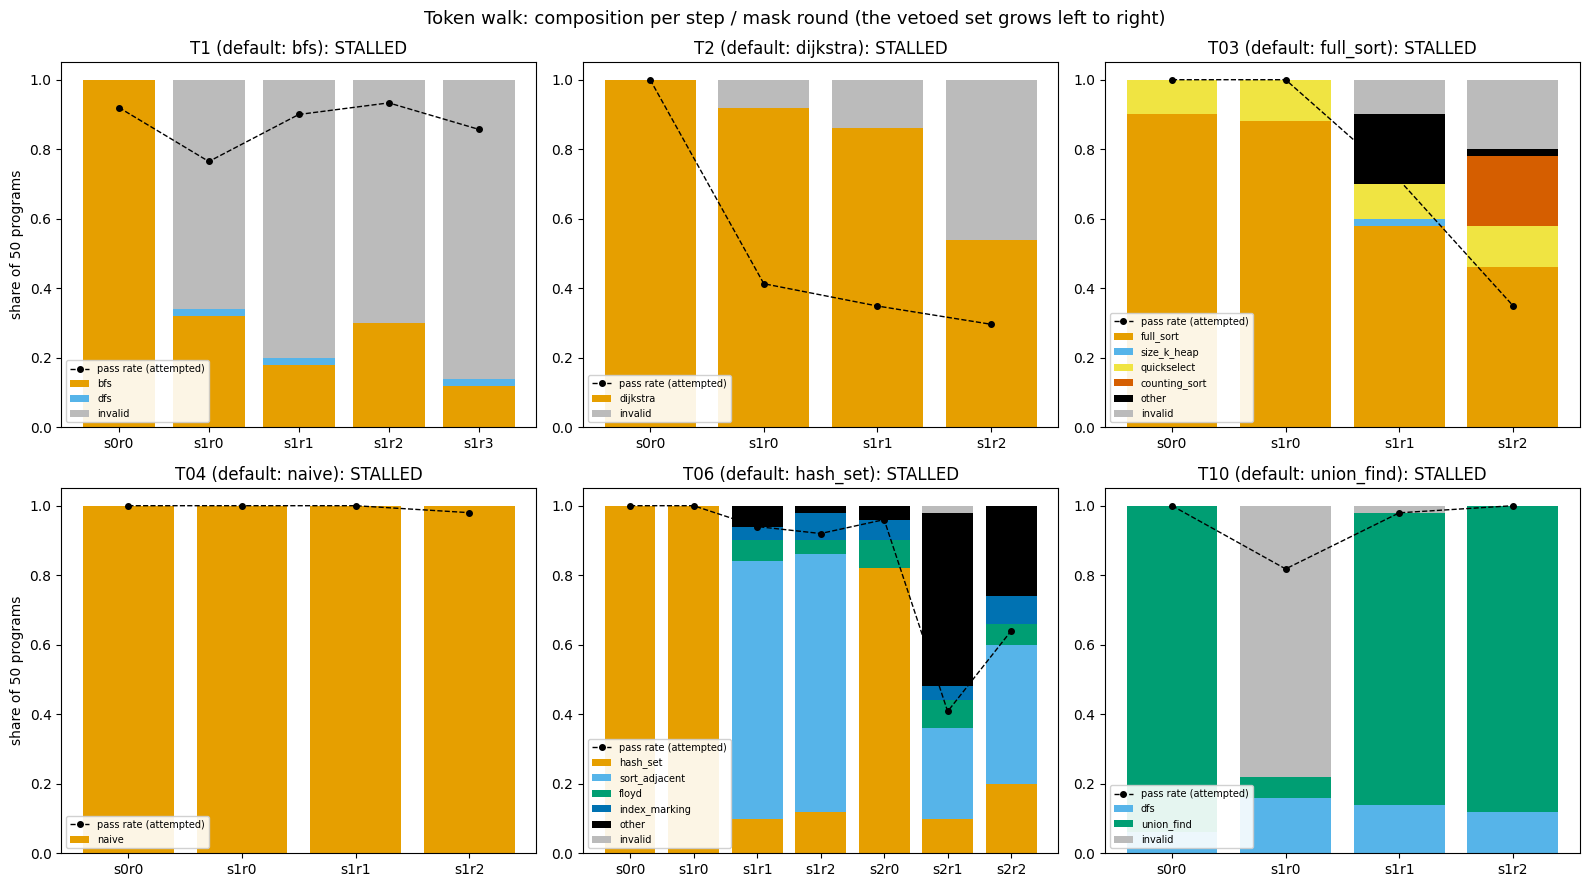

,task,added at,kind,algorithm,vetoed string,tokens
0,T1,s1r0,distinctive,bfs,"' c, path = queue.p'",6
1,T1,s1r1,reemergence,bfs,' queue.append(start',3
2,T1,s1r2,reemergence,bfs,'None for',2
3,T2,s1r0,distinctive,dijkstra,"' heap = [(0, s'",6
4,T2,s1r1,reemergence,dijkstra,"' current_dist,'",3
5,T2,s1r2,reemergence,dijkstra,' dist[u]:\n',3
6,T03,s1r0,distinctive,full_sort,' nums.sort',2
7,T03,s1r1,reemergence,full_sort,'_sorted',1
8,T03,s1r2,reemergence,full_sort,' sorted(nums',2
9,T04,s1r0,distinctive,naive,'+len',1


banned-sequence occurrences in the full run's 1100 vetoed walk generations: 0


In [17]:
# Adapted from src/figures.py (colour_map, fig_walk): same data and encodings, drawn inline in a 2 x 3 grid.
OKABE = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#999999", "#000000"]


def colour_map(labels: list[str]) -> dict[str, str]:
    cm, i = {}, 0
    for l in labels:
        if l == "invalid":
            cm[l] = "#BBBBBB"
        elif l == "other":
            cm[l] = "#000000"
        else:
            cm[l] = OKABE[i % 7]
            i += 1
    return cm


walk_full = json.loads(FILES["results/walk.json"])   # src/analysis.py over all 1,750 generations
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, t in zip(axes.flat, ALL_TASKS):
    steps = walk_full[t]["steps"]
    labs = TASKS[t]["catalogue"] + ["other", "invalid"]
    cm = colour_map(labs)
    xs = [f"s{s['step']}r{s['round']}" for s in steps]
    bottom = [0.0] * len(steps)
    for l in labs:
        vals = [s["counts"].get(l, 0) / max(1, s["n"]) for s in steps]
        if sum(vals) == 0:
            continue
        ax.bar(xs, vals, bottom=bottom, color=cm[l], label=l, width=0.8)
        bottom = [b + v for b, v in zip(bottom, vals)]
    ax.plot(xs, [s["pass_rate"] or 0 for s in steps], "k--", marker="o", ms=4, lw=1, label="pass rate (attempted)")
    ax.set_title(f"{t} (default: {TASKS[t]['default']}): {walk_full[t]['status']}")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7, loc="lower left", framealpha=0.9)
for ax in axes[:, 0]:
    ax.set_ylabel("share of 50 programs")
fig.suptitle("Token walk: composition per step / mask round (the vetoed set grows left to right)", fontsize=13)
fig.tight_layout()
plt.show()

masks = pd.DataFrame([{"task": t, "added at": f"s{m['step']}r{m['round']}", "kind": m["kind"], "algorithm": m["algo"],
                       "vetoed string": repr(m["string"]), "tokens": len(m["ids"])}
                      for t in ALL_TASKS for m in walk_full[t]["mask_items"]])
with pd.option_context("display.max_rows", 100):
    display(masks)
_vw = [s for t in ALL_TASKS for s in walk_full[t]["steps"] if s["step"] >= 1]
print(f"banned-sequence occurrences in the full run's {sum(s['n'] for s in _vw)} vetoed walk generations:",
      sum(s["veto_occurrences_total"] for s in _vw))

### 4. Controls: sham veto, and fixed TOP5 veto vs a prompt ban

**Left: sham vs distinctive veto** (step 1, first mask round). The sham vetoes an n-gram of matched length and presence that every algorithm uses (e.g. `' u, v, w'` on T2), so it tests whether *any* veto disturbs the model. Under the sham the default stays, at a share of valid programs of 0.98–1.00 (the prediction was ≥ 0.9). The distinctive veto keeps the default as well on T1, T2 and T04 (0.94–1.00), but it costs correctness: the T2 pass rate falls from 100% to 41%, and 66% of T1 programs become invalid.

T10 is the exception in the first round. 78% of its programs became invalid, and 8 of the 11 valid ones were DFS. Once the leaked spellings of `parent` were vetoed too, union-find came back (44/50 in the last round, see the figure above). No sham can be built for T03 and T06 (D4).

**Right: fixed TOP5 veto (T1).** Vetoing the distinctive n-grams of BFS, DFS, IDDFS and A*/greedy at once leaves BFS or invalid code in every round. exp9's TOP5 *prompt* ban gave avoidance 0 (BFS 63, DFS 36). Neither knob reaches the rest of the catalogue (bidirectional BFS, unit-weight Dijkstra).

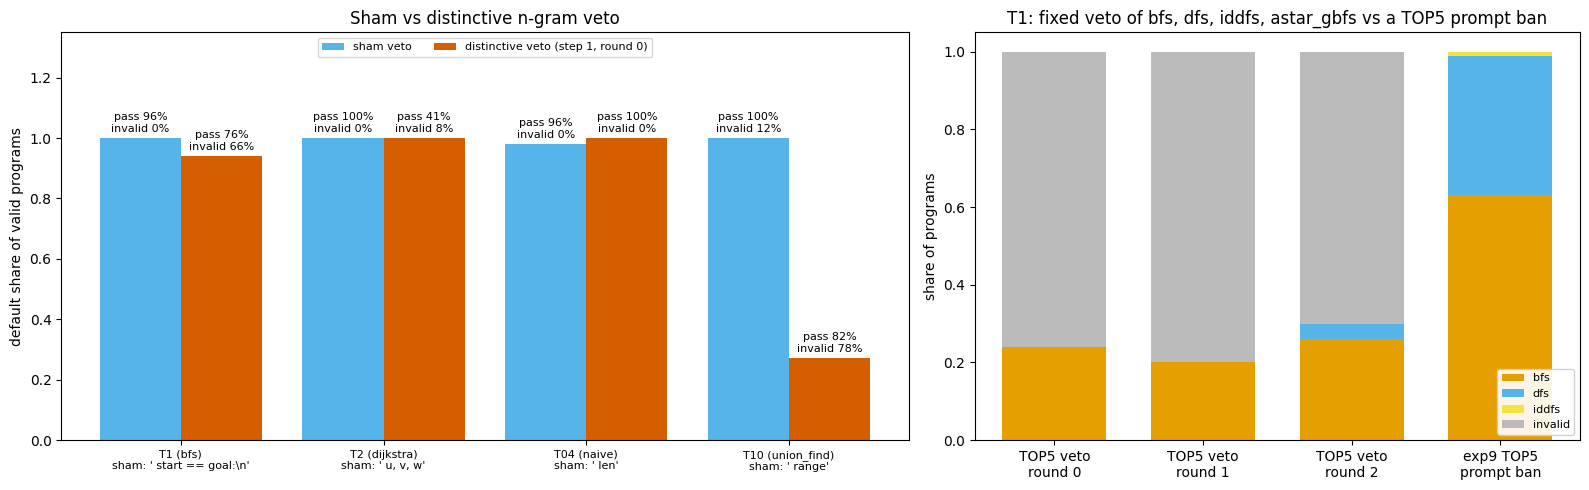

In [18]:
# Left: adapted from src/figures.py fig_sham (bars: default share of valid programs; labels: pass rate and invalid
# share). Right: the fixed TOP5 veto rounds next to exp9's TOP5 prompt ban (both from results/walk.json).
sv_rows = [(t, walk_full[t]["sham_vs_distinctive"]) for t in ALL_TASKS
           if "sham_ngram" in (walk_full[t].get("sham_vs_distinctive") or {})]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.4, 1]})
xs = range(len(sv_rows))
ax1.bar([x - 0.2 for x in xs], [r["sham_default_share"] or 0 for _, r in sv_rows], 0.4, color=OKABE[1],
        label="sham veto")
ax1.bar([x + 0.2 for x in xs], [r["distinctive_default_share"] or 0 for _, r in sv_rows], 0.4, color=OKABE[5],
        label="distinctive veto (step 1, round 0)")
for x, (_, r) in zip(xs, sv_rows):
    ax1.text(x - 0.2, (r["sham_default_share"] or 0) + 0.02,
             f"pass {r['sham_pass_rate']:.0%}\ninvalid {(r.get('sham_invalid_share') or 0):.0%}", ha="center", fontsize=8)
    ax1.text(x + 0.2, (r["distinctive_default_share"] or 0) + 0.02,
             f"pass {r['distinctive_pass_rate']:.0%}\ninvalid {(r.get('distinctive_invalid_share') or 0):.0%}",
             ha="center", fontsize=8)
ax1.set_xticks(list(xs))
ax1.set_xticklabels([f"{t} ({TASKS[t]['default']})\nsham: {r['sham_ngram']!r}" for t, r in sv_rows], fontsize=8)
ax1.set_ylabel("default share of valid programs")
ax1.set_ylim(0, 1.35)
ax1.legend(fontsize=8, loc="upper center", ncol=2)
ax1.set_title("Sham vs distinctive n-gram veto")

f5 = walk_full["fixed_top5_T1"]
p5 = f5["exp9_TOP5_prompt_ban"]
cols = [(f"TOP5 veto\nround {r['round']}", r["counts"], sum(r["counts"].values())) for r in f5["rounds"]]
cols.append(("exp9 TOP5\nprompt ban", {k.split(":", 1)[1]: v for k, v in p5["counts"].items()}, p5["n"]))
labs = TASKS["T1"]["catalogue"] + ["other", "invalid"]
cm = colour_map(labs)
bottom = [0.0] * len(cols)
for l in labs:
    vals = [cnt.get(l, 0) / n for _, cnt, n in cols]
    if sum(vals) == 0:
        continue
    ax2.bar([c[0] for c in cols], vals, bottom=bottom, color=cm[l], label=l, width=0.7)
    bottom = [b + v for b, v in zip(bottom, vals)]
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("share of programs")
ax2.legend(fontsize=8, loc="lower right", framealpha=0.9)
ax2.set_title(f"T1: fixed veto of {', '.join(f5['targets'])} vs a TOP5 prompt ban")
fig.tight_layout()
plt.show()

### 5. How the default comes back: programs from the processed subset

**Example programs.** A step-0 program of `EXAMPLE_TASK` (no veto) is printed next to `N_CODE_EXAMPLES` vetoed program(s) of the same task, one label at a time (the re-emerged default first, then broken code). Each comes with the committed mask that was in force, shown as tokens. On T1 the vetoed BFS comes back with renamed variables (`current_row, current_col` instead of `r, c`), or as near-miss syntax. With the token `.p` vetoed after `queue`, the model writes `queue popleft()` without the dot, which does not parse (`invalid`). The vetoed token sequence itself never appears.

**String leaks.** The veto bans token-id *sequences*, not strings, so the model can still write the vetoed text through a different tokenisation. Two examples:
- `' c, path = queue.p'` written with the single token `.pop` instead of `.p`, in `r, c, path = queue.pop()`. That line pops from the end of the list, and the program is labelled DFS.
- `'(parent'` instead of `' parent'`.

Leaked spellings, and the re-emerged programs' own distinctive n-grams, were added to the mask in the next round. That is what rounds `r1` and `r2` are.

In [19]:
def _mask(t, arm, step, rnd):
    """The committed mask in force for (arm, task, step, round): predictions/<arm>_<task>_s<step>_r<round>.json."""
    p = f"predictions/{arm}_{t}_s{step}_r{rnd}.json"
    return json.loads(FILES[p])["mask_items"] if p in FILES else []


tok = data["token_strings"]           # token id -> text (Qwen3-8B tokenizer), for every id in a mask or a leak span
D = TASKS[EXAMPLE_TASK]["default"]
walk_ex = [e for e in out["datasets"][0]["examples"]
           if e["metadata_arm"] == "walk" and e["metadata_task"] == EXAMPLE_TASK]
base = [e for e in walk_ex if e["metadata_step"] == 0]
by_label = {}                         # vetoed programs by label, earliest round first
for e in sorted([e for e in walk_ex if e["metadata_step"] >= 1],
                key=lambda e: (e["metadata_step"], e["metadata_round"])):
    by_label.setdefault(e["output"].split("|")[0], []).append(e)
order = sorted(by_label, key=lambda l: (l != D, l != "invalid", l))   # re-emerged default, invalid, others
vet = []
while any(by_label.values()):         # one program per label in turn
    for l in order:
        if by_label[l]:
            vet.append(by_label[l].pop(0))
print(f"=== {EXAMPLE_TASK}, step 0 (no veto), template {base[0]['metadata_template']}: {base[0]['output']}\n")
print(base[0]["metadata_code"])
for e in vet[:N_CODE_EXAMPLES]:
    s, r = e["metadata_step"], e["metadata_round"]
    vetoed = [[tok[str(i)] for i in m["ids"]] for m in _mask(EXAMPLE_TASK, "walk", s, r)]
    print(f"\n=== {EXAMPLE_TASK}, step {s} round {r}, template {e['metadata_template']}: {e['output']}\n"
          f"    committed mask (tokens): {vetoed}\n    = {e['metadata_n_veto_seqs']} vetoed sequences with their "
          f"newline / no-space variants; occurrences in this output: {e['metadata_veto_occurrences']}\n")
    print(e["metadata_code"])

leaks = [r for a in ("walk", "sham", "fixed_top5") for r in FILES[f"data/samples_{a}.jsonl"] if r.get("string_leak")]
print(f"\n=== String leaks among the processed generations: {len(leaks)}")
for r in leaks:
    it = r["leak_detail"][0]
    m = next((m for m in _mask(r["task"], r["arm"], r["step"], r["round"]) if m["string"] == it["string"]), {"ids": []})
    line = next((l.strip() for l in (r.get("code") or "").splitlines() if it["core"] in l), "")
    print(f"{r['task']:4s} {r['arm']:10s} s{r['step']}r{r['round']} -> {r['label']:10s} vetoed "
          f"{[tok.get(str(i), '?') for i in m['ids']]}, written as {[tok.get(str(i), '?') for i in it['spans'][0]]} "
          f"in {line!r}")
if not leaks:
    _n = sum(bool(r.get("string_leak")) for a in ("walk", "sham", "fixed_top5")
             for r in data["files"][f"data/samples_{a}.jsonl"])
    print(f"none in this subset; ROWS_PER_GROUP = None includes the {_n} shipped generations with a string leak")

=== T1, step 0 (no veto), template W1: bfs|pass

from collections import deque

def solve(grid, start, goal):
    if not grid or not grid[0]:
        return []
    rows, cols = len(grid), len(grid[0])
    start_row, start_col = start
    goal_row, goal_col = goal

    if (start_row < 0 or start_row >= rows or start_col < 0 or start_col >= cols or
        grid[start_row][start_col] == '#' or
        grid[goal_row][goal_col] == '#'):
        return []

    if start == goal:
        return [start]

    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    queue = deque()
    queue.append((start_row, start_col, [start]))
    visited = set()
    visited.add((start_row, start_col))

    while queue:
        r, c, path = queue.popleft()
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] == '.' and (nr, nc) not in visited:
                if (nr, nc) == (goal_row, goal_col):
                    return path + [(

## Summary

**What ran.** `method.py`'s `outputs` command (`assemble_outputs()`) on `ROWS_PER_GROUP` shipped generation(s) per (arm, task, step, round) group of the token-walk dataset. It also re-verified the preregistration hash chain over the byte-exact committed masks, forecasts and scripts. The code is the artifact's own; the `# demo:` lines point file reads at `data` and take the command from `CMD` instead of `sys.argv`.

**What it shows.**
- **The veto is exact.** No vetoed token sequence occurs in any vetoed generation: 0 in the 1,450 of the full run.
- **It does not move the model.** The walk stalled at the default on five of six tasks and at rung 2 on T06. Qwen3-8B routes around the veto lexically and keeps the algorithm: it renames variables, writes the vetoed string through other tokens (`.pop` for `.p`, `(parent` for ` parent`, `s =(set())`), or produces broken code.
- **The controls agree.** A matched sham veto leaves the default untouched. The distinctive veto mostly costs correctness (T2 pass rate 100% → 41%). Vetoing the n-grams of BFS, DFS, IDDFS and A*/greedy at once (fixed TOP5) leaves BFS or broken code.
- **Conclusion.** The choice of algorithm is not carried by one decisive surface token, so token-level bans do not open up the rest of the repertoire. The artifact's other parts (4a prompt reach, 4c long-form novelty) are summarised in the metadata above; no arm produced a correct novel algorithm.

**Scaling up.**
- `ROWS_PER_GROUP = None` processes all 100 shipped generations.
- The complete run (1,750 token-walk generations plus the prompt-reach, long-form and audit datasets) needs the artifact repository's `data/` and `results/` folders: `uv run method.py outputs` there rebuilds the full `method_out.json`.
- Regenerating the samples needs the Qwen3-8B (bf16) and Qwen3-8B-FP8 weights, vLLM 0.11 with the `src/veto.py` logits processor and a GPU with ≥ 23 GB. Run the commands in the order of `method.py`'s docstring (`CMD = "help"` prints it).